# AutoPilotRL — v5: continuous steering on a racetrack (REINFORCE and PPO)

## Where we are (highway, v1–v4)
| Driver | Return | Crash rate | Mean speed |
|---|---|---|---|
| v1 rule-based | 22.83 | **2%** | 22.5 m/s |
| v2 Q-learning | 23.05 | 8% | 23.0 m/s |
| v3 DQN | 20.55 | 18% | 21.9 m/s |
| v4 attention + Double + Dueling DQN | **26.83** | 10% | **28.5 m/s** |

## What changes in v5: we take the steering wheel
Until v4 the agent pressed one of **5 buttons** (LANE_LEFT, IDLE, …) once per second, and a hand-written controller inside highway-env did the actual steering.

Now the action is the **steering angle itself**: a real number $a \in [-1, 1]$, which highway-env multiplies by 45°, chosen 5 times per second.

### Why DQN no longer works
DQN acts greedily, $a^* = \arg\max_a Q(s, a)$: with 5 actions we simply try all 5.

With a continuous action there are infinitely many actions, so the max cannot be computed by trying them. (Some methods work around it, such as DDPG and SAC; SAC comes in v6.)

### Policy gradient: learn the policy directly
Instead of learning values and deriving the policy from them, a network outputs a **probability distribution over actions**, $\pi_\theta(a \mid s)$, and we push it towards the actions that turned out well.

For a steering angle the natural choice is a **Gaussian**: the network gives the mean steering, and a learned width $\sigma$ controls how much the agent explores.

We build two algorithms from scratch:
1. **REINFORCE** (Williams, 1992): the simplest policy gradient;
2. **PPO** (Schulman et al., 2017): *Proximal Policy Optimization*, the workhorse of modern RL (it is also the algorithm used to fine-tune language models with RLHF).

## The environment: `racetrack-v0`
- A closed circuit with **2 lanes**, 5 m wide, about **350 m** per lap, with several curves.
- Our car drives at a **fixed 10 m/s**: the agent controls only the steering.
- One **slower car** (6–9 m/s) starts ahead of us, in our lane. We will catch up with it, so **the agent must learn to overtake** or it will crash.
- **Observation:** an *occupancy grid* of 12 × 12 cells of 3 m around the car, rotated with the car, with 2 layers:
  - `presence`: where the cars are;
  - `on_road`: which cells are road.
- **Reward** at every step, in $[0, 1]$:

$$r = \text{map}_{[-1,1] \to [0,1]}\Big(\underbrace{\tfrac{1}{1 + 4\,y_{lat}^2}}_{\text{stay in the lane centre}} \;-\; 0.3\,|a| \;-\; 1 \cdot \text{crashed}\Big) \times \text{on\_road}$$

  where $y_{lat}$ is the distance in metres from the centre of the lane, and $|a|$ penalises steering (smooth driving).
- **End of episode:**
  - *terminated*: the car crashes or leaves the road;
  - *truncated*: after 40 s (200 decisions). The default is 300 s; we cut it to about one lap to keep training fast.
- The best possible return is therefore about **200**.

### Why the agent does not control the throttle
The reward has **no term for progress**. With a throttle, the best policy would be to **stop** in the middle of the lane: perfect centring, no risk of crashing.

It is the lesson of v4 again: **the agent optimises the reward we write, not what we mean.** With a fixed speed, the only way to collect reward is to drive.

## Plan
1. The environment and what the agent sees.
2. Baselines: random steering, straight wheel, and a **lane keeper** that cheats: it reads the lane geometry from the simulator, but is blind to the other car.
3. The Gaussian policy network and the value network.
4. **REINFORCE** with a baseline, 40,000 steps.
5. **PPO** with GAE, 100,000 steps.
6. Learning curves, test on 50 fixed scenarios, steering traces and a GIF.

Running time: about **30–45 minutes** on the CPU (the training cells print an estimate after the first steps). Run everything with **Run All**.

In [1]:
# --- LIBRARIES ---

# Gymnasium: the standard interface for RL environments.
import gymnasium as gym

# Registers the highway-env environments (including the racetrack).
import highway_env

# Numerical computing.
import numpy as np

# PyTorch: tensors and neural networks.
import torch

# Neural network layers.
import torch.nn as nn

# Loss functions.
import torch.nn.functional as F

# Probability distributions (the Gaussian policy).
from torch.distributions import Normal

# Plotting.
import matplotlib.pyplot as plt

# Build GIF animations from frames.
from PIL import Image as PILImage

# Show images and GIFs in the notebook.
from IPython.display import Image, display

# Independent copies of the best weights.
import copy

# File and folder paths.
from pathlib import Path

# Results file.
import json

# Measure time.
import time

# Silence warnings we do not need.
import warnings

# racetrack-v0 prints a "out of date" deprecation warning: v0 is fine for us.
warnings.filterwarnings("ignore", message=".*out of date.*")

# Folder for the videos.
VIDEO_DIR = Path("videos")

# Create it if needed.
VIDEO_DIR.mkdir(exist_ok=True)

# Folder for the results and the trained models.
RESULTS_DIR = Path("results")

# Create it if needed.
RESULTS_DIR.mkdir(exist_ok=True)

# The racetrack environment.
ENV_NAME = "racetrack-v0"

# Small networks, simulator on the CPU: the CPU is the fastest choice here.
device = torch.device("cpu")

# Reproducibility for PyTorch.
torch.manual_seed(0)

# Versions.
print(f"torch {torch.__version__} | gymnasium {gym.__version__}")

torch 2.14.1 | gymnasium 1.4.0


## Step 1 — The environment and what the agent sees

We create three copies of the same environment, as in v1–v4:
- `env` for training;
- `env_eval` for validation and test, so that evaluating never disturbs a training episode;
- `env_render` for the videos.

The only change to the default configuration is the episode length: **40 s** instead of 300 s.

The action space is `Box(-1, 1, (1,))`: one real number, the steering. highway-env maps it to an angle in $[-45°, +45°]$.

The observation has shape `(2, 12, 12)`:
- the first index is the **layer** (0 = presence of cars, 1 = road);
- the second index is the position **along** our car, from 18 m behind (index 0) to 18 m ahead (index 11);
- the third index is the position **across** our car, from 18 m on the left (index 0) to 18 m on the right (index 11).

Our own car is also in the presence layer, in the centre of the grid.

In the picture below, the grids are drawn with the car **driving upwards**: what is ahead is at the top.

In [2]:
# --- ENVIRONMENTS ---

# The only change to the defaults: episodes of 40 seconds (200 decisions at 5 Hz) instead of 300.
ENV_CONFIG = {"duration": 40}

# Training environment.
env = gym.make(ENV_NAME, config=ENV_CONFIG)

# Evaluation environment.
env_eval = gym.make(ENV_NAME, config=ENV_CONFIG)

# Video environment.
env_render = gym.make(ENV_NAME, render_mode="rgb_array", config=ENV_CONFIG)

# The settings that matter for us.
for key in ["duration", "policy_frequency", "simulation_frequency", "lane_centering_cost", "action_reward",
            "collision_reward", "terminate_off_road", "other_vehicles"]:

    # One line per setting.
    print(f"{key:<22} {env.unwrapped.config[key]}")

# Spaces.
print("\nAction space:     ", env.action_space)

# Observation space.
print("Observation space:", env.observation_space)

# Shape of one observation.
OBS_SHAPE = env.observation_space.shape

# Number of numbers the networks receive (2 x 12 x 12).
OBS_DIM = int(np.prod(OBS_SHAPE))

# Decisions per second.
POLICY_HZ = env.unwrapped.config["policy_frequency"]

# One step, to see the reward and its components.
obs, info = env.reset(seed=0)

# Straight wheel.
obs, reward, terminated, truncated, info = env.step(np.array([0.0], dtype=np.float32))

# Reward and components.
print(f"\nReward of one step: {reward:.3f}")

# The parts the reward is built from.
print("Components:", {k: round(float(v), 3) for k, v in info["rewards"].items()})

# Speed of our car (fixed).
print(f"Speed of our car: {info['speed']:.1f} m/s")

duration               40
policy_frequency       5
simulation_frequency   15
lane_centering_cost    4
action_reward          -0.3
collision_reward       -1
terminate_off_road     True
other_vehicles         1

Action space:      Box(-1.0, 1.0, (1,), float32)
Observation space: Box(-inf, inf, (2, 12, 12), float32)

Reward of one step: 1.000
Components: {'lane_centering_reward': 1.0, 'action_reward': 0.0, 'collision_reward': 0.0, 'on_road_reward': 1.0}
Speed of our car: 10.0 m/s


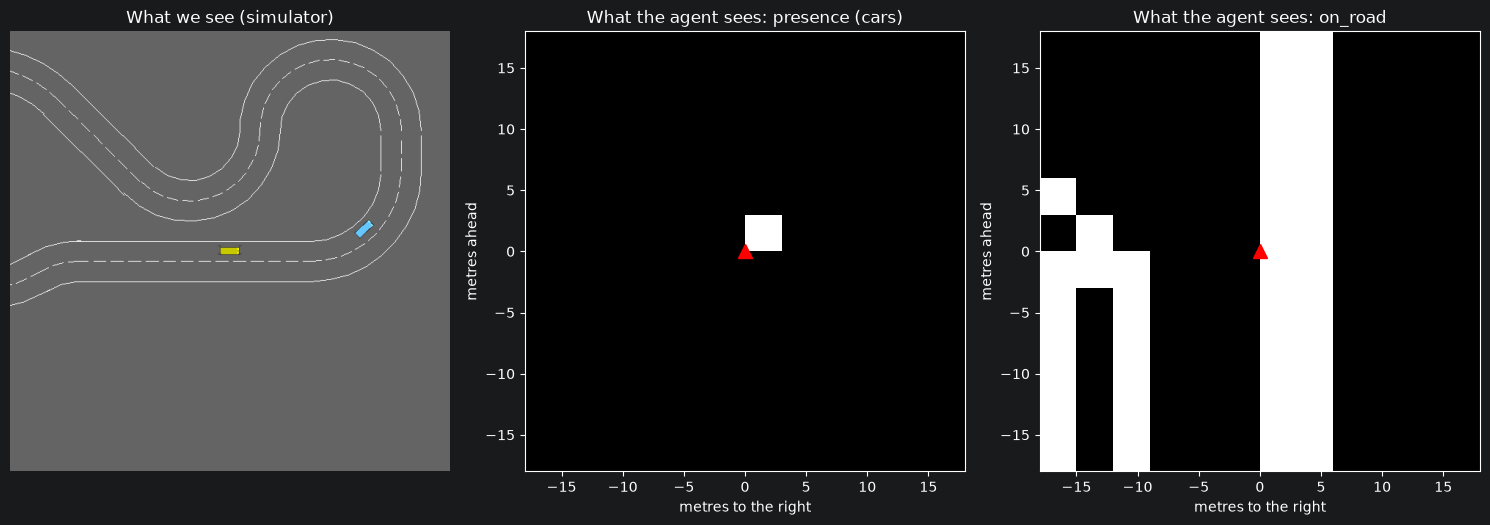

In [3]:
# --- WHAT THE AGENT SEES ---

# Start a test scenario in the video environment.
obs, _ = env_render.reset(seed=1000)

# The picture a human would see.
frame = env_render.render()

# Three panels: simulator picture, presence layer, road layer.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# The simulator picture.
axes[0].imshow(frame)

# Title.
axes[0].set_title("What we see (simulator)")

# No axes on a picture.
axes[0].axis("off")

# The two layers of the observation.
for ax, layer, name in zip(axes[1:], [0, 1], ["presence (cars)", "on_road"]):

    # Rows = along the car (row 0 = behind): origin="lower" puts "ahead" at the top. Columns = left to right.
    ax.imshow(obs[layer], origin="lower", cmap="gray", vmin=0, vmax=1, extent=[-18, 18, -18, 18])

    # Our car, at the centre.
    ax.plot(0, 0, marker="^", color="red", markersize=10)

    # Title.
    ax.set_title(f"What the agent sees: {name}")

    # Axis labels.
    ax.set_xlabel("metres to the right")

    # Vertical axis.
    ax.set_ylabel("metres ahead")

# Render.
plt.tight_layout()

# Show.
plt.show()

## Step 2 — Evaluation and baselines

### The test protocol
As in v1–v4: **50 fixed test scenarios** (seeds 1000–1049). The seed fixes where our car starts and where the slower car is. Validation uses other seeds (2000–2009) and training others again (from 10,000), so the test scenarios are never used to choose anything.

For each episode we measure:
- the **return** (at most about 200);
- how it ended: **finished** (40 s without problems), **crash** (hit the other car), or **off road**;
- the **time** survived, in seconds;
- the mean **|offset|**: distance from the lane centre, in metres.

### Videos
At 5 decisions per second an episode has up to 200 decisions. To keep the GIFs small we keep one frame per decision, reduced to 300 × 300 pixels, and play them at 10 frames per second (twice real time).

### Three baselines
1. **Random**: a random steering in $[-1, 1]$ at every step.
2. **Straight**: the wheel stays at 0, so the car leaves the road at the first curve.
3. **Lane keeper**: a classical controller that **cheats**: it reads its position in the lane from the simulator, which the agent never sees. It steers to correct two errors:

$$\delta = K_\psi \cdot \text{wrap}\big(\psi_{lane}(s + L) - \psi\big) \;-\; K_y \cdot y_{lat}, \qquad a = \text{clip}\Big(\frac{\delta}{\pi/4}, -1, 1\Big)$$

- $\psi$ is the heading of our car, and $\psi_{lane}(s + L)$ is the direction of the lane $L = 5$ m ahead of our position $s$: the heading error makes it follow the curves;
- $y_{lat}$ is the distance from the lane centre: the second term brings it back to the centre;
- `wrap` keeps the angle difference in $[-\pi, \pi]$;
- $K_\psi = 1.0$, $K_y = 0.3$.

It drives the circuit perfectly, but it **ignores the other car**: it should crash into it when it catches up. The RL agents must learn to keep the lane **from the grid alone** and to overtake.

In [4]:
# --- EVALUATION ---

# The 50 fixed test scenarios.
EVAL_SEEDS = list(range(1000, 1050))

# Validation scenarios, used to choose the best model during training.
VAL_SEEDS = list(range(2000, 2010))


# Signed distance of our car from the centre of its lane, in metres.
def lateral_offset(env):
    """Read from the simulator (the agent never sees this number)."""

    # Our car.
    vehicle = env.unwrapped.vehicle

    # Position in lane coordinates: (along the lane, across the lane).
    _, lateral = vehicle.lane.local_coordinates(vehicle.position)

    # The lateral part.
    return lateral


# Run a policy on a list of scenarios and measure it.
def evaluate(policy, seeds=EVAL_SEEDS, env=env_eval):
    """policy(env, obs) -> action array of shape (1,). Returns a dict of per-episode arrays."""

    # Per-episode measurements.
    returns, finished, crashes, off_road, lengths, offsets = [], [], [], [], [], []

    # One episode per seed.
    for seed in seeds:

        # Start the episode.
        obs, info = env.reset(seed=seed)

        # Return, steps and offsets of this episode.
        episode_return, steps, episode_offsets = 0.0, 0, []

        # Until the episode ends.
        done = False

        # Play.
        while not done:

            # The policy chooses a steering.
            action = policy(env, obs)

            # One step.
            obs, reward, terminated, truncated, info = env.step(action)

            # Accumulate the reward.
            episode_return += reward

            # One more decision.
            steps += 1

            # Distance from the lane centre.
            episode_offsets.append(abs(lateral_offset(env)))

            # End of the episode?
            done = terminated or truncated

        # Our car at the end.
        vehicle = env.unwrapped.vehicle

        # Store the return.
        returns.append(episode_return)

        # Reached the time limit without a crash or leaving the road.
        finished.append(truncated and not terminated)

        # Hit the other car.
        crashes.append(bool(vehicle.crashed))

        # Left the road.
        off_road.append(not vehicle.on_road)

        # Seconds survived.
        lengths.append(steps / POLICY_HZ)

        # Mean distance from the lane centre.
        offsets.append(np.mean(episode_offsets))

    # Everything as NumPy arrays.
    return {"return": np.array(returns), "finished": np.array(finished, dtype=float),
            "crash": np.array(crashes, dtype=float), "off_road": np.array(off_road, dtype=float),
            "time": np.array(lengths), "offset": np.array(offsets)}


# One line summary of an evaluation.
def summary(name, res):
    """Print the mean of every metric."""

    # Means.
    print(f"{name:<14} return {res['return'].mean():6.1f} | finished {res['finished'].mean():4.0%} | "
          f"crash {res['crash'].mean():4.0%} | off road {res['off_road'].mean():4.0%} | "
          f"time {res['time'].mean():4.1f} s | |offset| {res['offset'].mean():4.2f} m")


# --- VIDEOS ---

# Play one episode with rendering and save it as a GIF.
def record_episode(policy, seed, filename, env=env_render, size=300):
    """Return (path of the GIF, return of the episode, how it ended)."""

    # Start the episode.
    obs, info = env.reset(seed=seed)

    # First frame, reduced in size.
    frames = [PILImage.fromarray(env.render()).resize((size, size))]

    # Return of the episode.
    episode_return = 0.0

    # Until the episode ends.
    done = False

    # Play.
    while not done:

        # One decision.
        obs, reward, terminated, truncated, info = env.step(policy(env, obs))

        # Accumulate the reward.
        episode_return += reward

        # One frame per decision.
        frames.append(PILImage.fromarray(env.render()).resize((size, size)))

        # End?
        done = terminated or truncated

    # Our car at the end.
    vehicle = env.unwrapped.vehicle

    # How it ended.
    outcome = "CRASH" if vehicle.crashed else ("OFF ROAD" if not vehicle.on_road else "finished")

    # Path of the GIF.
    path = VIDEO_DIR / filename

    # Save: 100 ms per frame = 10 frames per second = twice real time (5 decisions per second); loop forever.
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=100, loop=0)

    # Path, return and outcome.
    return path, episode_return, outcome


# Record an episode and show it in the notebook.
def show_episode(policy, seed, filename, title, env=env_render):
    """Save the GIF, print the outcome and display the animation."""

    # Record it.
    path, episode_return, outcome = record_episode(policy, seed, filename, env=env)

    # Outcome.
    print(f"{title}: return {episode_return:.1f}, {outcome}  ({path})")

    # The animation.
    display(Image(filename=str(path)))

random         return    5.5 | finished   0% | crash   0% | off road 100% | time  2.1 s | |offset| 1.40 m
straight       return   16.2 | finished   0% | crash   0% | off road 100% | time  3.9 s | |offset| 0.52 m
lane keeper    return   71.3 | finished   4% | crash  96% | off road   0% | time 17.0 s | |offset| 0.26 m
Lane keeper, scenario 1000: return 35.3, CRASH  (videos/v5_lane_keeper.gif)


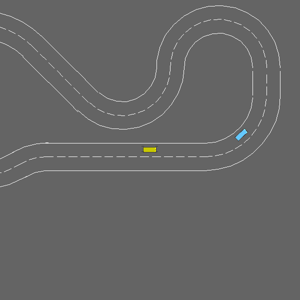

In [5]:
# --- BASELINES ---

# Random generator for the random driver (its own, so that it is reproducible).
rng = np.random.default_rng(0)


# Random steering at every step.
def random_driver(env, obs):
    """Uniform in [-1, 1]."""

    # One random number, as a float32 array of shape (1,).
    return rng.uniform(-1, 1, size=1).astype(np.float32)


# Wheel always straight.
def straight_driver(env, obs):
    """Steering 0."""

    # Zero steering.
    return np.zeros(1, dtype=np.float32)


# Heading error gain.
K_HEADING = 1.0

# Lateral error gain (per metre).
K_LATERAL = 0.3

# How far ahead along the lane we read its direction (metres).
LOOKAHEAD = 5.0


# Classical controller that reads the lane geometry from the simulator.
def lane_keeper(env, obs):
    """Follows the centre of its lane; blind to the other car."""

    # Our car.
    vehicle = env.unwrapped.vehicle

    # The lane it is in.
    lane = vehicle.lane

    # Position along the lane (s) and distance from its centre (lateral).
    s, lateral = lane.local_coordinates(vehicle.position)

    # Direction of the lane a few metres ahead minus our heading.
    heading_error = lane.heading_at(s + LOOKAHEAD) - vehicle.heading

    # Wrap the difference into [-pi, pi].
    heading_error = (heading_error + np.pi) % (2 * np.pi) - np.pi

    # Steering angle: follow the curve, and come back to the centre.
    angle = K_HEADING * heading_error - K_LATERAL * lateral

    # As an action in [-1, 1] (the environment maps 1 to 45 degrees = pi / 4).
    return np.array([np.clip(angle / (np.pi / 4), -1, 1)], dtype=np.float32)


# All test results, by driver name.
results = {}

# Evaluate the three baselines.
for name, driver in [("random", random_driver), ("straight", straight_driver), ("lane keeper", lane_keeper)]:

    # 50 test scenarios.
    results[name] = evaluate(driver)

    # Report.
    summary(name, results[name])

# The lane keeper on the usual scenario.
show_episode(lane_keeper, seed=1000, filename="v5_lane_keeper.gif", title="Lane keeper, scenario 1000")

## Step 3 — A policy that outputs a probability distribution

### The Gaussian policy
The **actor** network receives the grid (288 numbers) and outputs the **mean** steering $\mu_\theta(s)$. The action is drawn from a Gaussian:

$$a \sim \mathcal{N}\big(\mu_\theta(s), \sigma^2\big), \qquad \log \pi_\theta(a \mid s) = -\frac{(a - \mu_\theta(s))^2}{2\sigma^2} - \log \sigma - \tfrac{1}{2}\log 2\pi$$

- $\sigma$ is a **learned parameter** (one number, the same in every state; we learn $\log\sigma$ so that $\sigma$ stays positive).
- $\sigma$ is the **exploration**: at the start it is large (about 0.6), and as the agent becomes confident the gradient makes it smaller. It plays the role that ε had in DQN, but now the agent tunes it itself.
- The sampled action can fall outside $[-1, 1]$: we clip it before sending it to the simulator, but we compute $\log\pi$ on the **unclipped** sample, which is the one that was really drawn.
- For evaluation we drive **deterministically**: $a = \text{clip}(\mu_\theta(s))$, without noise.

The last layer of the mean starts with very small weights, so that the initial mean is about 0 (straight wheel) in every state.

### The value network (critic)
Both algorithms also use a **value** network $V_\phi(s)$, which estimates the expected discounted return from state $s$:

$$V_\phi(s) \approx \mathbb{E}\Big[\sum_{k \ge 0} \gamma^k r_{t+k} \;\Big|\; s_t = s\Big]$$

It is not used to choose actions. It tells us whether an action did **better or worse than expected**, which is what the policy gradient needs (next steps).

Both networks are small MLPs: 288 → 64 → 64, with `tanh` activations (the usual choice for policy gradient).

In [6]:
# --- NETWORKS ---

# Width of the hidden layers.
HIDDEN = 64


# Actor: grid -> Gaussian distribution over the steering.
class GaussianPolicy(nn.Module):
    """mean = MLP(grid); std = exp(log_std), a learned parameter shared by all states."""

    # Build the layers.
    def __init__(self, obs_dim=OBS_DIM, hidden=HIDDEN, init_log_std=-0.5):

        # Initialise nn.Module.
        super().__init__()

        # Shared body: flatten (2, 12, 12) -> 288, then two hidden layers with tanh.
        self.body = nn.Sequential(
            nn.Flatten(),
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
        )

        # Mean of the steering (one number).
        self.mean_head = nn.Linear(hidden, 1)

        # Start with a mean of about 0 in every state: tiny weights, zero bias.
        with torch.no_grad():

            # Shrink the weights.
            self.mean_head.weight.mul_(0.01)

            # Zero bias.
            self.mean_head.bias.zero_()

        # Log of the standard deviation (exp(-0.5) = 0.61 at the start).
        self.log_std = nn.Parameter(torch.full((1,), init_log_std))

    # Forward pass: the distribution of the action in each state.
    def forward(self, obs):
        """obs: (B, 2, 12, 12) -> Normal with mean and std of shape (B, 1)."""

        # Mean steering.
        mean = self.mean_head(self.body(obs))

        # Same standard deviation for every state in the batch.
        std = self.log_std.exp().expand_as(mean)

        # The Gaussian distribution.
        return Normal(mean, std)


# Critic: grid -> one number, the value of the state.
class ValueNet(nn.Module):
    """V(s) = MLP(grid)."""

    # Build the layers.
    def __init__(self, obs_dim=OBS_DIM, hidden=HIDDEN):

        # Initialise nn.Module.
        super().__init__()

        # Same shape as the actor, with one output.
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )

    # Forward pass.
    def forward(self, obs):
        """obs: (B, 2, 12, 12) -> values (B,)."""

        # Remove the last dimension of size 1.
        return self.net(obs).squeeze(-1)


# One observation as a batch of size 1.
def as_batch(obs):
    """NumPy (2, 12, 12) -> tensor (1, 2, 12, 12)."""

    # Add the batch dimension.
    return torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)


# Sample an action for training (with exploration).
@torch.no_grad()
def sample_action(policy, obs):
    """Return the unclipped sample, shape (1,)."""

    # Draw from the Gaussian.
    return policy(as_batch(obs)).sample()[0].numpy()


# Turn a trained policy into a deterministic driver for evaluate().
def make_driver(policy):
    """driver(env, obs) -> clip(mean)."""

    # The driver function.
    @torch.no_grad()
    def drive(env, obs):

        # The mean of the Gaussian, no noise.
        mean = policy(as_batch(obs)).mean[0].numpy()

        # Inside the valid range.
        return np.clip(mean, -1, 1).astype(np.float32)

    # Return it.
    return drive


# A quick check.
check_policy, check_value = GaussianPolicy(), ValueNet()

# Number of trainable numbers.
print(f"Actor parameters:  {sum(p.numel() for p in check_policy.parameters()):,}")

# Critic size.
print(f"Critic parameters: {sum(p.numel() for p in check_value.parameters()):,}")

# A distribution for the last observation.
dist = check_policy(as_batch(obs))

# Its mean and width.
print(f"Initial mean {dist.mean.item():+.4f} | initial std {dist.stddev.item():.3f} | value {check_value(as_batch(obs)).item():+.3f}")

# Five samples: the initial exploration.
print("Five samples:", np.round([sample_action(check_policy, obs)[0] for _ in range(5)], 2))

Actor parameters:  22,722
Critic parameters: 22,721
Initial mean -0.0000 | initial std 0.607 | value -0.069
Five samples: [-0.86  0.29  0.23 -0.24  0.23]


## Step 4 — REINFORCE

### The policy gradient theorem
We want the parameters $\theta$ that maximise the expected return $J(\theta) = \mathbb{E}_{\pi_\theta}\big[\sum_t \gamma^t r_t\big]$. Its gradient can be written as an expectation over the episodes the policy itself plays:

$$\nabla_\theta J(\theta) = \mathbb{E}_{\pi_\theta}\Big[\sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\; G_t\Big], \qquad G_t = \sum_{k \ge 0} \gamma^k r_{t+k}$$

- $\nabla_\theta \log \pi_\theta(a_t \mid s_t)$ is the direction that makes action $a_t$ **more likely** in state $s_t$.
- It is weighted by $G_t$, the return obtained **after** that action.

So actions followed by a high return become more likely, and actions followed by a low one less likely. No $\max$ over actions is needed anywhere, which is why it works with continuous actions.

### The baseline: subtract what we expected
All returns here are positive, so every action would be pushed up, just some more than others. This is very noisy. We subtract a **baseline** that depends only on the state:

$$A_t = G_t - V_\phi(s_t)$$

- $A_t > 0$: the action did better than expected, so it becomes more likely.
- $A_t < 0$: worse than expected, so it becomes less likely.

The baseline does not bias the gradient, because $\mathbb{E}_{a \sim \pi}\big[\nabla_\theta \log \pi_\theta(a \mid s)\big] \, b(s) = 0$. It only reduces the variance. We also **normalise** the advantages of a batch (mean 0, std 1) to keep the step size stable.

### The losses we minimise
$$\mathcal{L}_{actor} = -\frac{1}{N}\sum_t \log \pi_\theta(a_t \mid s_t)\, \hat{A}_t \qquad \mathcal{L}_{critic} = \frac{1}{N}\sum_t \big(G_t - V_\phi(s_t)\big)^2$$

Each network has its own Adam optimiser, and gradients are clipped to norm 0.5.

### The algorithm
1. Play **4 complete episodes** with the current policy (with exploration).
2. Compute $G_t$ for every step, going backwards: $G_t = r_t + \gamma\, G_{t+1}$.
3. One gradient step on both losses, then **throw the data away**: the next update needs episodes from the new policy.

| Setting | Value |
|---|---|
| Environment steps | 40,000 |
| Episodes per update | 4 |
| Discount γ | 0.99 (5 decisions per second: a horizon of about 20 s) |
| Learning rate | 1e-3 (actor and critic) |
| Validation | every 10,000 steps, on 10 scenarios (deterministic driving) |

**A known weakness:** an episode cut at 40 s is treated as if it really ended there. The last steps then get small returns, and the critic cannot know why, because the time is not in the observation. PPO fixes this.

In [7]:
# --- REINFORCE TRAINING ---

# Total environment steps.
RF_STEPS = 40_000

# Complete episodes per gradient step.
RF_EPISODES_PER_UPDATE = 4

# Discount factor.
GAMMA = 0.99

# Learning rate.
RF_LR = 1e-3

# Gradient clipping norm.
MAX_GRAD_NORM = 0.5

# Validate every this many environment steps.
VAL_EVERY = 10_000


# Discounted returns of one episode, computed backwards.
def discounted_returns(rewards, gamma=GAMMA):
    """G_t = r_t + gamma * G_{t+1}."""

    # Return after the last step.
    g = 0.0

    # Returns, filled backwards.
    out = []

    # From the last reward to the first.
    for r in reversed(rewards):

        # Bellman-like recursion.
        g = r + gamma * g

        # Store.
        out.append(g)

    # Back to time order.
    return out[::-1]


# Mean validation return of a policy (deterministic driving).
def validate(policy):
    """Mean return on the validation scenarios."""

    # Evaluate on the validation seeds.
    return evaluate(make_driver(policy), seeds=VAL_SEEDS)["return"].mean()


# Train with REINFORCE.
def train_reinforce():
    """Return (best policy, training log)."""

    # Same starting weights every run.
    torch.manual_seed(0)

    # Actor and critic.
    policy, value = GaussianPolicy(), ValueNet()

    # One optimiser each.
    actor_opt = torch.optim.Adam(policy.parameters(), lr=RF_LR)

    # Critic optimiser.
    critic_opt = torch.optim.Adam(value.parameters(), lr=RF_LR)

    # Training log.
    log = {"steps": [], "return": [], "val_steps": [], "val_return": [], "sigma_steps": [], "sigma": []}

    # Environment steps so far.
    steps = 0

    # Training scenarios (never the test or validation ones).
    seed = 10_000

    # Next validation.
    next_val = VAL_EVERY

    # Best validation so far, and its weights.
    best_val, best_state = -np.inf, None

    # Clock.
    start = time.time()

    # Until the step budget is used.
    while steps < RF_STEPS:

        # The data of this update.
        batch_obs, batch_actions, batch_returns = [], [], []

        # A few complete episodes.
        for _ in range(RF_EPISODES_PER_UPDATE):

            # New training scenario.
            obs, _ = env.reset(seed=seed)

            # Next scenario.
            seed += 1

            # Rewards of this episode.
            rewards = []

            # Until the end.
            done = False

            # Play with exploration.
            while not done:

                # Sample a steering (unclipped).
                action = sample_action(policy, obs)

                # The simulator receives it clipped.
                next_obs, reward, terminated, truncated, _ = env.step(np.clip(action, -1, 1))

                # Store the state, the action really sampled, and the reward.
                batch_obs.append(obs)

                # Action.
                batch_actions.append(action)

                # Reward.
                rewards.append(reward)

                # Move on.
                obs = next_obs

                # Count the step.
                steps += 1

                # End?
                done = terminated or truncated

            # Returns of every step of this episode.
            batch_returns.extend(discounted_returns(rewards))

            # Log the undiscounted return of the episode.
            log["steps"].append(steps)

            # Return.
            log["return"].append(sum(rewards))

        # The batch as tensors.
        obs_t = torch.as_tensor(np.array(batch_obs), dtype=torch.float32)

        # Actions (N, 1).
        actions_t = torch.as_tensor(np.array(batch_actions), dtype=torch.float32)

        # Returns (N,).
        returns_t = torch.as_tensor(np.array(batch_returns), dtype=torch.float32)

        # Values predicted by the critic.
        values = value(obs_t)

        # Advantages: return minus baseline (no gradient through the baseline).
        advantages = returns_t - values.detach()

        # Normalise them.
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        # log pi(a|s) of the actions taken (sum over the action dimensions: just one here).
        log_probs = policy(obs_t).log_prob(actions_t).sum(dim=1)

        # Policy gradient loss.
        actor_loss = -(log_probs * advantages).mean()

        # Clear the old gradients.
        actor_opt.zero_grad()

        # Backpropagation.
        actor_loss.backward()

        # Clip the gradient.
        nn.utils.clip_grad_norm_(policy.parameters(), MAX_GRAD_NORM)

        # Update the actor.
        actor_opt.step()

        # Critic loss: predict the returns.
        critic_loss = F.mse_loss(values, returns_t)

        # Clear the old gradients.
        critic_opt.zero_grad()

        # Backpropagation.
        critic_loss.backward()

        # Clip the gradient.
        nn.utils.clip_grad_norm_(value.parameters(), MAX_GRAD_NORM)

        # Update the critic.
        critic_opt.step()

        # Log the exploration width.
        log["sigma_steps"].append(steps)

        # Current std.
        log["sigma"].append(policy.log_std.exp().item())

        # After the first update: a time estimate.
        if len(log["sigma"]) == 1:

            # Milliseconds per environment step.
            ms = (time.time() - start) / steps * 1000

            # Estimate for both algorithms.
            print(f"{ms:.1f} ms/step so far -> REINFORCE about {ms * RF_STEPS / 60000:.0f} min, "
                  f"PPO about {ms * 100_000 / 60000:.0f} min (plus validations)")

        # Time to validate?
        if steps >= next_val:

            # Next validation.
            next_val += VAL_EVERY

            # Deterministic driving on the validation scenarios.
            val_return = validate(policy)

            # Log.
            log["val_steps"].append(steps)

            # Return.
            log["val_return"].append(val_return)

            # Best so far?
            if val_return > best_val:

                # Remember it.
                best_val, best_state = val_return, copy.deepcopy(policy.state_dict())

            # Progress.
            print(f"step {steps:6d} | train return (last 20) {np.mean(log['return'][-20:]):6.1f} | "
                  f"val return {val_return:6.1f} | sigma {log['sigma'][-1]:.3f} | {time.time() - start:.0f}s")

    # Back to the best weights.
    policy.load_state_dict(best_state)

    # Report.
    print(f"\nBest validation return: {best_val:.1f}")

    # The trained actor and the log.
    return policy, log


# Train.
rf_policy, rf_log = train_reinforce()

# Save the best actor.
torch.save(rf_policy.state_dict(), RESULTS_DIR / "v5_reinforce.pt")

12.0 ms/step so far -> REINFORCE about 8 min, PPO about 20 min (plus validations)
step  10338 | train return (last 20)   58.7 | val return   64.8 | sigma 0.596 | 101s
step  20070 | train return (last 20)   67.6 | val return   79.5 | sigma 0.594 | 192s
step  30349 | train return (last 20)   75.5 | val return   93.5 | sigma 0.592 | 289s
step  40450 | train return (last 20)   89.6 | val return   96.1 | sigma 0.590 | 392s

Best validation return: 96.1


## Step 5 — PPO

REINFORCE has three problems:
1. it must wait for **complete episodes**, and the Monte Carlo return $G_t$ is very noisy;
2. every batch is used for **one** gradient step and then thrown away;
3. nothing stops a single step from changing the policy too much, and a bad policy then produces bad data to learn from.

PPO fixes all three.

### 1. GAE: advantages from the critic
The **TD error** compares what happened in one step with what the critic expected:

$$\delta_t = r_t + \gamma\, V_\phi(s_{t+1})\,(1 - d_t) - V_\phi(s_t)$$

where $d_t = 1$ if the episode ended at step $t$. **Generalized Advantage Estimation** (Schulman et al., 2016) mixes the TD errors of the following steps:

$$\hat{A}_t = \sum_{l \ge 0} (\gamma\lambda)^l\, \delta_{t+l} \qquad \text{computed backwards: } \hat{A}_t = \delta_t + \gamma\lambda\,(1 - d_t)\,\hat{A}_{t+1}$$

- $\lambda = 0$: $\hat{A}_t = \delta_t$, which has low variance but relies entirely on the critic (bias).
- $\lambda = 1$: $\hat{A}_t = G_t - V(s_t)$, exactly REINFORCE with a baseline (no bias, high variance).
- We use $\lambda = 0.95$, in between.

The critic learns to predict $\hat{R}_t = \hat{A}_t + V_{\phi_{old}}(s_t)$.

Because the critic fills in the future, we do not need complete episodes: we collect a **rollout of 2,048 steps**, possibly spanning several episodes.

### Time limits done right
When an episode is cut at 40 s, the car did not really stop: the future was just not played. So at a **truncation** we add the critic's estimate of the missing future to the last reward, $r_t \leftarrow r_t + \gamma V_\phi(s_{t+1})$, and then treat the episode as ended. A **termination** (crash, off road) really ends everything: nothing is added.

### 2. Reuse the data: the probability ratio
We do **10 epochs** over each rollout, in minibatches of 64. After the first minibatch, however, the policy is no longer the one that collected the data. The **probability ratio** corrects for this:

$$\rho_t(\theta) = \frac{\pi_\theta(a_t \mid s_t)}{\pi_{\theta_{old}}(a_t \mid s_t)} = \exp\big(\log\pi_\theta(a_t \mid s_t) - \log\pi_{\theta_{old}}(a_t \mid s_t)\big)$$

- $\rho_t > 1$: the new policy makes $a_t$ more likely than the old one did.
- The objective $\rho_t \hat{A}_t$ has the same gradient as REINFORCE at $\theta = \theta_{old}$.

### 3. Do not move too far: the clipped objective

$$\mathcal{L}^{CLIP}(\theta) = \mathbb{E}_t\Big[\min\big(\rho_t(\theta)\,\hat{A}_t,\; \text{clip}(\rho_t(\theta), 1 - \epsilon, 1 + \epsilon)\,\hat{A}_t\big)\Big], \qquad \epsilon = 0.2$$

- If $\hat{A}_t > 0$ (good action), raising its probability pays only up to $\rho_t = 1.2$; beyond that the gradient is zero.
- If $\hat{A}_t < 0$ (bad action), lowering its probability pays only down to $\rho_t = 0.8$.
- The `min` makes the objective **pessimistic**: the clip removes the incentive to move further, never the penalty for having moved in the wrong direction.

We maximise $\mathcal{L}^{CLIP}$, so we minimise $-\mathcal{L}^{CLIP}$. An entropy bonus can also be added to keep exploring; here its coefficient is 0, and the learned σ does the job.

### Two diagnostics
- **Clip fraction**: the share of samples whose ratio left $[0.8, 1.2]$. It measures how hard the clip is working; typical values are 0.05–0.25.
- **Approximate KL divergence** $\approx \mathbb{E}[\log\pi_{old} - \log\pi_\theta]$: how far the policy moved during the update; typical values are around 0.01.

| Setting | Value |
|---|---|
| Environment steps | 100,000 (48 rollouts) |
| Rollout length | 2,048 steps |
| Epochs × minibatch | 10 × 64 |
| γ, λ | 0.99, 0.95 |
| Clip ε | 0.2 |
| Learning rate | 3e-4 (actor and critic) |
| Validation | every 10,000 steps, 10 scenarios |

In [8]:
# --- PPO TRAINING ---

# Total environment steps.
PPO_STEPS = 100_000

# Steps collected before each update.
ROLLOUT = 2048

# Passes over each rollout.
EPOCHS = 10

# Minibatch size.
MINIBATCH = 64

# Clip range of the probability ratio.
CLIP_EPS = 0.2

# GAE parameter.
LAMBDA = 0.95

# Learning rate.
PPO_LR = 3e-4

# Entropy bonus coefficient (0: the learned sigma handles exploration).
ENT_COEF = 0.0


# GAE advantages of one rollout, computed backwards.
def compute_gae(rewards, values, dones, last_value):
    """All arrays of length ROLLOUT; last_value = V of the state after the last step. Returns (advantages, returns)."""

    # Advantages, filled backwards.
    advantages = np.zeros(len(rewards), dtype=np.float32)

    # Advantage of the step after the current one.
    gae = 0.0

    # From the last step to the first.
    for t in reversed(range(len(rewards))):

        # Value of the next state: the bootstrap after the last step, otherwise the stored value.
        next_value = last_value if t == len(rewards) - 1 else values[t + 1]

        # 0 if the episode ended at step t (do not look across episodes), 1 otherwise.
        not_done = 1.0 - dones[t]

        # TD error.
        delta = rewards[t] + GAMMA * next_value * not_done - values[t]

        # Recursion of GAE.
        gae = delta + GAMMA * LAMBDA * not_done * gae

        # Store.
        advantages[t] = gae

    # Targets of the critic.
    return advantages, advantages + values


# Train with PPO.
def train_ppo():
    """Return (best policy, training log)."""

    # Same starting weights every run.
    torch.manual_seed(0)

    # Actor and critic.
    policy, value = GaussianPolicy(), ValueNet()

    # One optimiser each.
    actor_opt = torch.optim.Adam(policy.parameters(), lr=PPO_LR)

    # Critic optimiser.
    critic_opt = torch.optim.Adam(value.parameters(), lr=PPO_LR)

    # Training log.
    log = {"steps": [], "return": [], "val_steps": [], "val_return": [], "sigma_steps": [], "sigma": [],
           "clip_frac": [], "kl": []}

    # Training scenarios.
    seed = 10_000

    # First episode.
    obs, _ = env.reset(seed=seed)

    # Next scenario.
    seed += 1

    # Return of the current episode.
    episode_return = 0.0

    # Environment steps so far.
    steps = 0

    # Next validation.
    next_val = VAL_EVERY

    # Best validation so far, and its weights.
    best_val, best_state = -np.inf, None

    # Clock.
    start = time.time()

    # Number of rollouts.
    n_iterations = PPO_STEPS // ROLLOUT

    # One rollout + one update per iteration.
    for iteration in range(n_iterations):

        # Rollout storage.
        buf_obs = np.zeros((ROLLOUT, *OBS_SHAPE), dtype=np.float32)

        # Actions (unclipped samples).
        buf_actions = np.zeros((ROLLOUT, 1), dtype=np.float32)

        # log pi_old(a|s).
        buf_log_probs = np.zeros(ROLLOUT, dtype=np.float32)

        # Rewards.
        buf_rewards = np.zeros(ROLLOUT, dtype=np.float32)

        # Values V_old(s).
        buf_values = np.zeros(ROLLOUT, dtype=np.float32)

        # Episode ended at this step.
        buf_dones = np.zeros(ROLLOUT, dtype=np.float32)

        # --- 1. COLLECT A ROLLOUT ---
        for t in range(ROLLOUT):

            # No gradients while acting.
            with torch.no_grad():

                # Distribution in the current state.
                dist = policy(as_batch(obs))

                # Sample a steering.
                action = dist.sample()

                # Its log-probability.
                log_prob = dist.log_prob(action).sum(dim=1)

                # Value of the current state.
                v = value(as_batch(obs))

            # One step with the clipped action.
            next_obs, reward, terminated, truncated, _ = env.step(np.clip(action[0].numpy(), -1, 1))

            # Real return of the episode (for the learning curve).
            episode_return += reward

            # Count the step.
            steps += 1

            # Cut by the time limit: add the critic's estimate of the missing future.
            if truncated and not terminated:

                # No gradients.
                with torch.no_grad():

                    # Bootstrap.
                    reward += GAMMA * value(as_batch(next_obs)).item()

            # Store the transition.
            buf_obs[t] = obs

            # Action.
            buf_actions[t] = action[0].numpy()

            # log pi_old.
            buf_log_probs[t] = log_prob.item()

            # Reward (with the bootstrap if truncated).
            buf_rewards[t] = reward

            # V_old(s).
            buf_values[t] = v.item()

            # Did the episode end here?
            buf_dones[t] = float(terminated or truncated)

            # End of the episode?
            if terminated or truncated:

                # Log it.
                log["steps"].append(steps)

                # Return.
                log["return"].append(episode_return)

                # Reset the counter.
                episode_return = 0.0

                # New training scenario.
                obs, _ = env.reset(seed=seed)

                # Next scenario.
                seed += 1

            # Otherwise continue the episode.
            else:

                # Move on.
                obs = next_obs

        # Value of the state after the rollout (the episode may continue in the next rollout).
        with torch.no_grad():

            # Bootstrap value.
            last_value = value(as_batch(obs)).item()

        # --- 2. ADVANTAGES ---
        advantages, returns = compute_gae(buf_rewards, buf_values, buf_dones, last_value)

        # Everything as tensors.
        obs_t = torch.as_tensor(buf_obs)

        # Actions.
        actions_t = torch.as_tensor(buf_actions)

        # Old log-probabilities.
        old_log_probs_t = torch.as_tensor(buf_log_probs)

        # Advantages.
        advantages_t = torch.as_tensor(advantages)

        # Critic targets.
        returns_t = torch.as_tensor(returns)

        # Diagnostics of this update.
        clip_fracs, kls = [], []

        # --- 3. SEVERAL EPOCHS OF MINIBATCH UPDATES ---
        for epoch in range(EPOCHS):

            # A new random order of the rollout.
            order = torch.randperm(ROLLOUT)

            # Minibatches.
            for start_idx in range(0, ROLLOUT, MINIBATCH):

                # Indices of this minibatch.
                idx = order[start_idx:start_idx + MINIBATCH]

                # Distribution of the current policy.
                dist = policy(obs_t[idx])

                # New log pi(a|s) of the stored actions.
                new_log_probs = dist.log_prob(actions_t[idx]).sum(dim=1)

                # Probability ratio.
                ratio = torch.exp(new_log_probs - old_log_probs_t[idx])

                # Advantages, normalised within the minibatch.
                adv = advantages_t[idx]

                # Mean 0, std 1.
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)

                # Unclipped objective.
                surrogate1 = ratio * adv

                # Clipped objective.
                surrogate2 = torch.clamp(ratio, 1 - CLIP_EPS, 1 + CLIP_EPS) * adv

                # Pessimistic minimum, minus the entropy bonus.
                actor_loss = -torch.min(surrogate1, surrogate2).mean() - ENT_COEF * dist.entropy().sum(dim=1).mean()

                # Clear the old gradients.
                actor_opt.zero_grad()

                # Backpropagation.
                actor_loss.backward()

                # Clip the gradient.
                nn.utils.clip_grad_norm_(policy.parameters(), MAX_GRAD_NORM)

                # Update the actor.
                actor_opt.step()

                # Critic loss.
                critic_loss = F.mse_loss(value(obs_t[idx]), returns_t[idx])

                # Clear the old gradients.
                critic_opt.zero_grad()

                # Backpropagation.
                critic_loss.backward()

                # Clip the gradient.
                nn.utils.clip_grad_norm_(value.parameters(), MAX_GRAD_NORM)

                # Update the critic.
                critic_opt.step()

                # Diagnostics, without gradients.
                with torch.no_grad():

                    # Share of samples outside [1 - eps, 1 + eps].
                    clip_fracs.append(((ratio - 1).abs() > CLIP_EPS).float().mean().item())

                    # Approximate KL divergence between old and new policy.
                    kls.append((old_log_probs_t[idx] - new_log_probs).mean().item())

        # Log the update.
        log["sigma_steps"].append(steps)

        # Exploration width.
        log["sigma"].append(policy.log_std.exp().item())

        # Mean clip fraction.
        log["clip_frac"].append(np.mean(clip_fracs))

        # Mean approximate KL.
        log["kl"].append(np.mean(kls))

        # After the first update: a time estimate.
        if iteration == 0:

            # Seconds per rollout + update.
            seconds = time.time() - start

            # Estimate.
            print(f"{seconds:.0f} s per rollout + update -> about {seconds * n_iterations / 60:.0f} min (plus validations)")

        # Time to validate?
        if steps >= next_val:

            # Next validation.
            next_val += VAL_EVERY

            # Deterministic driving on the validation scenarios.
            val_return = validate(policy)

            # Log.
            log["val_steps"].append(steps)

            # Return.
            log["val_return"].append(val_return)

            # Best so far?
            if val_return > best_val:

                # Remember it.
                best_val, best_state = val_return, copy.deepcopy(policy.state_dict())

            # Progress.
            print(f"step {steps:6d} | train return (last 20) {np.mean(log['return'][-20:]):6.1f} | "
                  f"val return {val_return:6.1f} | sigma {log['sigma'][-1]:.3f} | "
                  f"clip frac {log['clip_frac'][-1]:.3f} | KL {log['kl'][-1]:.4f} | {time.time() - start:.0f}s")

    # Back to the best weights.
    policy.load_state_dict(best_state)

    # Report.
    print(f"\nBest validation return: {best_val:.1f}")

    # The trained actor and the log.
    return policy, log


# Train.
ppo_policy, ppo_log = train_ppo()

# Save the best actor.
torch.save(ppo_policy.state_dict(), RESULTS_DIR / "v5_ppo.pt")

21 s per rollout + update -> about 16 min (plus validations)
step  10240 | train return (last 20)   34.9 | val return   80.4 | sigma 0.500 | clip frac 0.144 | KL 0.0144 | 106s
step  20480 | train return (last 20)   67.8 | val return   96.7 | sigma 0.463 | clip frac 0.101 | KL 0.0114 | 213s
step  30720 | train return (last 20)   72.5 | val return  124.1 | sigma 0.431 | clip frac 0.156 | KL 0.0159 | 326s
step  40960 | train return (last 20)   90.4 | val return  127.8 | sigma 0.406 | clip frac 0.144 | KL 0.0171 | 427s
step  51200 | train return (last 20)  111.9 | val return  125.8 | sigma 0.380 | clip frac 0.192 | KL 0.0202 | 531s
step  61440 | train return (last 20)  107.8 | val return  129.7 | sigma 0.368 | clip frac 0.170 | KL 0.0181 | 636s
step  71680 | train return (last 20)  117.2 | val return  118.5 | sigma 0.346 | clip frac 0.173 | KL 0.0137 | 743s
step  81920 | train return (last 20)  110.5 | val return  126.5 | sigma 0.342 | clip frac 0.152 | KL 0.0158 | 848s
step  90112 | train

## Step 6 — Learning curves

Four panels:
1. **Training return** (moving average of 20 episodes, with exploration) against environment steps, with the lane keeper as reference.
2. **Validation return** (deterministic driving, 10 scenarios): the points used to pick the best model.
3. **σ**, the exploration width. It should shrink as each agent becomes confident.
4. PPO's **clip fraction** and **approximate KL**: how far each update moved the policy.

**What to look for:**
- Which algorithm gets more out of the same number of environment steps (*sample efficiency*). At 40,000 steps both curves can be compared directly.
- How noisy each curve is.
- Whether the return passes the lane keeper. That would mean the agent learned something the cheating controller cannot do: **avoiding the other car**.

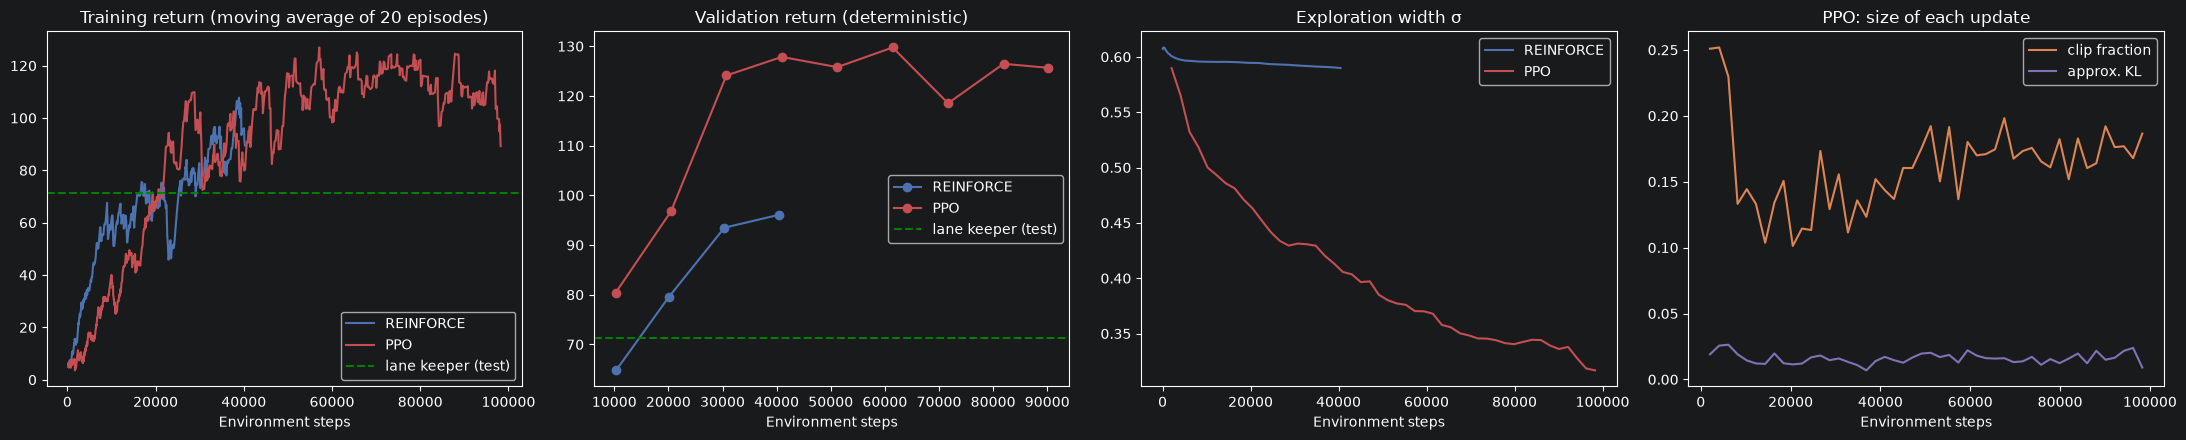

In [9]:
# --- LEARNING CURVES ---

# Moving average.
def moving_average(x, k=20):
    """Mean of the last k values (valid part only)."""

    # Convolution with a flat window.
    return np.convolve(x, np.ones(k) / k, mode="valid")


# Mean test return of the lane keeper, as a reference line.
lane_keeper_return = results["lane keeper"]["return"].mean()

# Four panels.
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))

# Training and validation curves of both algorithms.
for name, log, colour in [("REINFORCE", rf_log, "#4C72B0"), ("PPO", ppo_log, "#C44E52")]:

    # Smoothed training return.
    smooth = moving_average(np.array(log["return"]))

    # Plot it against the step of the last episode of each window.
    axes[0].plot(np.array(log["steps"])[len(log["steps"]) - len(smooth):], smooth, color=colour, label=name)

    # Validation return.
    axes[1].plot(log["val_steps"], log["val_return"], marker="o", color=colour, label=name)

    # Exploration width.
    axes[2].plot(log["sigma_steps"], log["sigma"], color=colour, label=name)

# Reference lines.
for ax in axes[:2]:

    # Lane keeper.
    ax.axhline(lane_keeper_return, color="green", linestyle="--", label="lane keeper (test)")

    # Legend.
    ax.legend()

    # x label.
    ax.set_xlabel("Environment steps")

# Titles.
axes[0].set_title("Training return (moving average of 20 episodes)")

# Validation panel.
axes[1].set_title("Validation return (deterministic)")

# Sigma panel.
axes[2].set_title("Exploration width σ")

# x label.
axes[2].set_xlabel("Environment steps")

# Legend.
axes[2].legend()

# PPO diagnostics.
axes[3].plot(ppo_log["sigma_steps"], ppo_log["clip_frac"], color="#DD8452", label="clip fraction")

# KL on the same panel.
axes[3].plot(ppo_log["sigma_steps"], ppo_log["kl"], color="#8172B3", label="approx. KL")

# Title.
axes[3].set_title("PPO: size of each update")

# x label.
axes[3].set_xlabel("Environment steps")

# Legend.
axes[3].legend()

# Layout.
plt.tight_layout()

# Show.
plt.show()

## Step 7 — Test on the 50 scenarios

Both agents drive **deterministically** ($a = \text{clip}(\mu_\theta(s))$) with their best validation weights, on the same 50 scenarios as the baselines.

Two charts:
- the mean **return** of each driver;
- **how the episodes end**: finished, crash (hit the other car), or off road.

The lane keeper never leaves the road, but it should crash. An agent that learned to overtake would *finish* episodes, which the lane keeper cannot do.

This evaluation plays up to 10,000 steps per agent: it takes a few minutes.

random         return    5.5 | finished   0% | crash   0% | off road 100% | time  2.1 s | |offset| 1.40 m
straight       return   16.2 | finished   0% | crash   0% | off road 100% | time  3.9 s | |offset| 0.52 m
lane keeper    return   71.3 | finished   4% | crash  96% | off road   0% | time 17.0 s | |offset| 0.26 m
v5 REINFORCE   return   97.0 | finished  62% | crash  38% | off road   0% | time 31.3 s | |offset| 0.74 m
v5 PPO         return  133.4 | finished  80% | crash  16% | off road   4% | time 36.1 s | |offset| 0.53 m


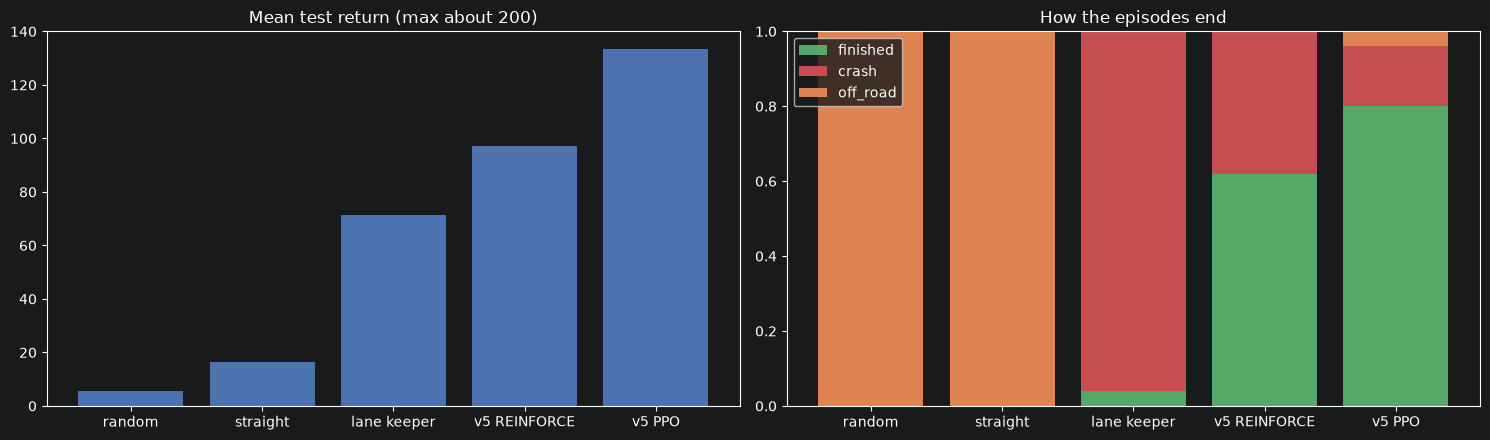


Saved results/racetrack_results.json


In [10]:
# --- TEST ---

# REINFORCE on the test scenarios.
results["v5 REINFORCE"] = evaluate(make_driver(rf_policy))

# PPO on the test scenarios.
results["v5 PPO"] = evaluate(make_driver(ppo_policy))

# All drivers.
for name, res in results.items():

    # One line each.
    summary(name, res)

# Driver names in order.
names = list(results.keys())

# Two panels.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Mean return of each driver.
axes[0].bar(names, [results[n]["return"].mean() for n in names], color="#4C72B0")

# Title.
axes[0].set_title("Mean test return (max about 200)")

# How the episodes end, stacked.
bottom = np.zeros(len(names))

# Three outcomes.
for outcome, colour in [("finished", "#55A868"), ("crash", "#C44E52"), ("off_road", "#DD8452")]:

    # Share of episodes with this outcome.
    share = np.array([results[n][outcome].mean() for n in names])

    # Stacked bar.
    axes[1].bar(names, share, bottom=bottom, color=colour, label=outcome)

    # Move the base up.
    bottom += share

# Title.
axes[1].set_title("How the episodes end")

# Legend.
axes[1].legend()

# Layout.
plt.tight_layout()

# Show.
plt.show()

# --- SAVE THE RESULTS ---

# Means of every driver (a new file: the racetrack metrics differ from the highway ones).
racetrack_results = {n: {metric: float(values.mean()) for metric, values in res.items()} for n, res in results.items()}

# Write the file.
(RESULTS_DIR / "racetrack_results.json").write_text(json.dumps(racetrack_results, indent=2))

# Confirm.
print("\nSaved results/racetrack_results.json")

## Step 8 — Inside the driver: steering and overtaking

On one test scenario we record, at every decision:
- the **steering** chosen, in $[-1, 1]$;
- the **distance to the other car**, read from the simulator;
- the **lane** our car is in (0 or 1).

We compare PPO with the lane keeper:
- the lane keeper should steer smoothly, stay in its lane, and stop when the distance reaches zero (the crash);
- an agent that overtakes should **change lane** while the distance is shrinking, pass the car, and keep driving.

Then the GIF of the PPO driver on scenario 1000, the same as the lane keeper's GIF in Step 2.

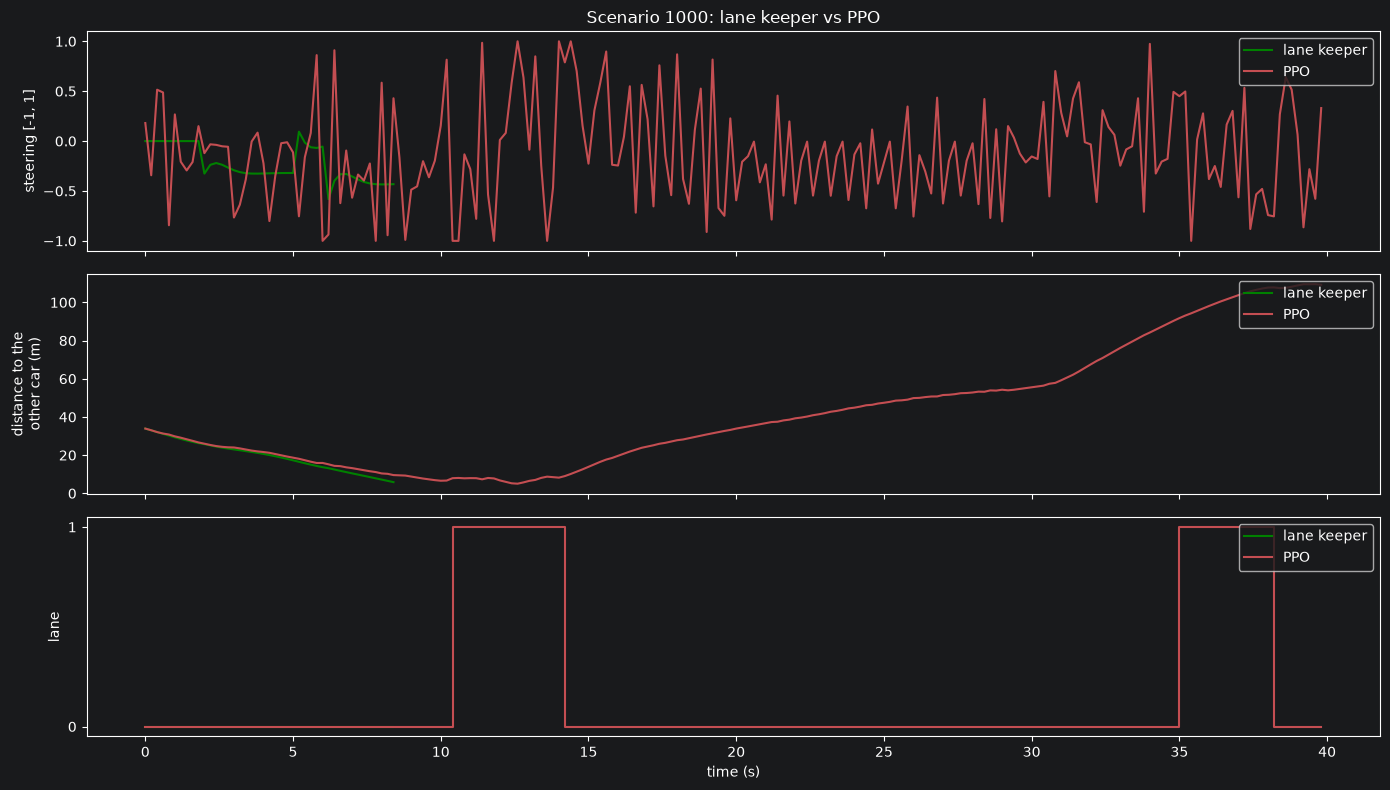

PPO, scenario 1000: return 146.9, finished  (videos/v5_ppo.gif)


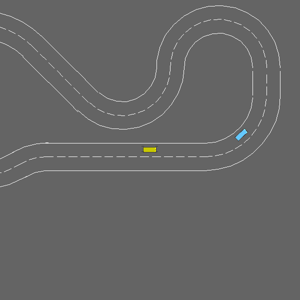

In [11]:
# --- STEERING TRACES ---

# Play one scenario and record steering, distance to the other car and lane.
def trace(driver, seed, env=env_eval):
    """Return three arrays, one value per decision."""

    # Start.
    obs, _ = env.reset(seed=seed)

    # Records.
    steering, distance, lane = [], [], []

    # Until the end.
    done = False

    # Play.
    while not done:

        # Steering of this decision.
        action = driver(env, obs)

        # Store it.
        steering.append(float(action[0]))

        # Our car.
        ego = env.unwrapped.vehicle

        # Distances to every other car.
        others = [np.linalg.norm(v.position - ego.position) for v in env.unwrapped.road.vehicles if v is not ego]

        # The nearest one (NaN if there is none).
        distance.append(min(others) if others else np.nan)

        # Lane index (last element of the lane identifier).
        lane.append(ego.lane_index[2])

        # Step.
        obs, _, terminated, truncated, _ = env.step(action)

        # End?
        done = terminated or truncated

    # As arrays.
    return np.array(steering), np.array(distance), np.array(lane)


# Three rows sharing the time axis.
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# Both drivers on the same scenario.
for name, driver, colour in [("lane keeper", lane_keeper, "green"), ("PPO", make_driver(ppo_policy), "#C44E52")]:

    # Record.
    steering, distance, lane = trace(driver, seed=1000)

    # Time in seconds.
    t = np.arange(len(steering)) / POLICY_HZ

    # Steering.
    axes[0].plot(t, steering, color=colour, label=name)

    # Distance to the other car.
    axes[1].plot(t, distance, color=colour, label=name)

    # Lane.
    axes[2].step(t, lane, color=colour, label=name, where="post")

# Labels.
axes[0].set_ylabel("steering [-1, 1]")

# Distance axis.
axes[1].set_ylabel("distance to the\nother car (m)")

# Lane axis.
axes[2].set_ylabel("lane")

# Only 0 and 1.
axes[2].set_yticks([0, 1])

# Time axis.
axes[2].set_xlabel("time (s)")

# Legends.
for ax in axes:

    # One legend per row.
    ax.legend(loc="upper right")

# Title.
axes[0].set_title("Scenario 1000: lane keeper vs PPO")

# Layout.
plt.tight_layout()

# Show.
plt.show()

# The PPO driver on the usual scenario.
show_episode(make_driver(ppo_policy), seed=1000, filename="v5_ppo.gif", title="PPO, scenario 1000")

## Results and conclusions

### Test results (50 scenarios, deterministic driving)
| Driver | Return | Finished | Crash | Off road | Time | Mean \|offset\| |
|---|---|---|---|---|---|---|
| random | 5.5 | 0% | 0% | 100% | 2.1 s | 1.40 m |
| straight | 16.2 | 0% | 0% | 100% | 3.9 s | 0.52 m |
| lane keeper (cheats) | 71.3 | 4% | **96%** | 0% | 17.0 s | **0.26 m** |
| v5 REINFORCE | 97.0 | 62% | 38% | 0% | 31.3 s | 0.74 m |
| **v5 PPO** | **133.4** | **80%** | 16% | 4% | **36.1 s** | 0.53 m |

### 1. Both agents learned to overtake, which the cheating controller cannot do
- The lane keeper follows the lane perfectly, but **crashes into the slower car in 96% of the scenarios**, after 17 s on average.
- Both RL agents beat it while seeing only a coarse 12 × 12 grid.
  - REINFORCE finishes 62% of the episodes.
  - PPO finishes **80%**.
- The trace of scenario 1000 shows the overtaking step by step:
  - the distance to the other car shrinks to about 5 m;
  - at 10.4 s PPO moves to the other lane;
  - it drives alongside the car at about 8 m;
  - at 14.2 s it returns to its lane;
  - after that the distance only grows, up to 100 m.
- In the same scenario the lane keeper crashes at 8.4 s.

The agent reacts late: it changes lane only at a few metres from the car. This matches what it can see. The grid covers ±18 m, and in the Step 1 picture the other car, 34 m ahead, is not in it at all.

### 2. PPO vs REINFORCE: same data, many more gradient steps
- At **40,000 steps** PPO already has a validation return of 127.8; REINFORCE has 96.1.
- REINFORCE uses each batch of 4 episodes for **one** gradient step and then throws it away: about a hundred updates in total.
- PPO makes 48 rollouts × 10 epochs × 32 minibatches = **15,360** gradient steps from 100,000 environment steps, and the clip keeps each one safe.
- **σ tells the same story.**
  - PPO reduces its exploration steadily, from 0.61 to 0.32.
  - REINFORCE barely moves it, from 0.61 to 0.59: after 40,000 steps it is still exploring like at the start.
  - Its validation return was still rising, so it was not finished; it is just much slower.
- The training curves of the two (with exploration noise) are close for the first 40,000 steps. The difference appears when the noise is removed (validation and test), because PPO has learned a sharper mean policy.

### 3. The PPO update is healthy
- The clip fraction stays at 0.10–0.20 and the approximate KL at 0.01–0.025: the usual ranges for PPO.
- No update moved the policy too far.
- The best validation return (129.7, at 61,440 steps) was confirmed on the test (133.4).
- The training return drops at the very end (about 90) while the validation stays around 125. Choosing the best validation checkpoint protects us from such late degradations.

### 4. The price: nervous steering
- The PPO steering jumps between −1 and +1 almost every step, while the lane keeper steers smoothly.
- PPO stays 0.53 m from the lane centre on average, double the lane keeper's 0.26 m.
- **PPO wins by surviving, not by driving better per step:**
  - PPO earns 133.4 / (36.1 × 5) = **0.74** per decision;
  - the lane keeper earns 71.3 / (17.0 × 5) = **0.84**.
- The main reason is the **observation**. Cells of 3 m on lanes 5 m wide cannot tell the agent precisely where it is in the lane, so it keeps correcting.
- The steering penalty (−0.3 · |a|) is too small, compared with surviving, to force smoothness.

Possible fixes:
- a finer grid, or adding the heading and the lane offset to the observation;
- a penalty on *changes* of steering;
- stacking two consecutive grids, so the agent can see its own motion.

### 5. Remaining failures
- **PPO:** 16% crashes (the overtaking starts too late) and 4% off road (2 episodes).
- **REINFORCE:** 38% crashes and never leaves the road. It learned to keep the lane but overtakes less often.

### 6. Next step
**v6: parking.** The agent controls **throttle and steering** (2 continuous actions) and must reach a parking spot that changes in every episode: a **goal-conditioned** task where success is hard to find by chance. We will use:
- **SAC** (Soft Actor-Critic): off-policy like DQN, with a replay buffer, plus an entropy bonus for exploration;
- **HER** (Hindsight Experience Replay): every failed attempt is re-used as a success at reaching *the place where the car actually ended up*.